# RetailLens
Synthetic retail analysis. Run `python -m retaillens.build` first. No real customer data.

In [1]:
from pathlib import Path
import sys, json
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root))
import pandas as pd
from retaillens.analysis import metrics, sql_metrics
lines=pd.read_csv(root/'data/clean/lines.csv')
records=lines.to_dict('records')
result=metrics(records)
assert result==sql_metrics(records)
result

{'gross': 23592200000,
 'discount': 1746203000,
 'refund': 981008250,
 'net': 20864988750,
 'orders': 11112,
 'customers': 912,
 'aov': 1877698.771598272,
 'repeat_rate': 79.27631578947368}

In [2]:
completed=lines[lines.status=='completed'].copy()
completed['net']=completed.gross-completed.discount-completed.refund
assert int(completed.net.sum())==result['net']
completed.groupby('category').net.sum().sort_values(ascending=False)

category
Home           3799208250
Books          3771346500
Beauty         3746861750
Fashion        3636199000
Sports         3047779000
Electronics    2367683250
Unknown         495911000
Name: net, dtype: int64

In [3]:
quality=pd.read_csv(root/'reports/data_quality.csv')
quality.groupby(['reason','action']).size()

reason                 action        
duplicate_id           quarantined       2
invalid_amount         quarantined       1
invalid_customer_link  quarantined       1
invalid_date           quarantined       1
missing_category       filled_unknown    1
dtype: int64

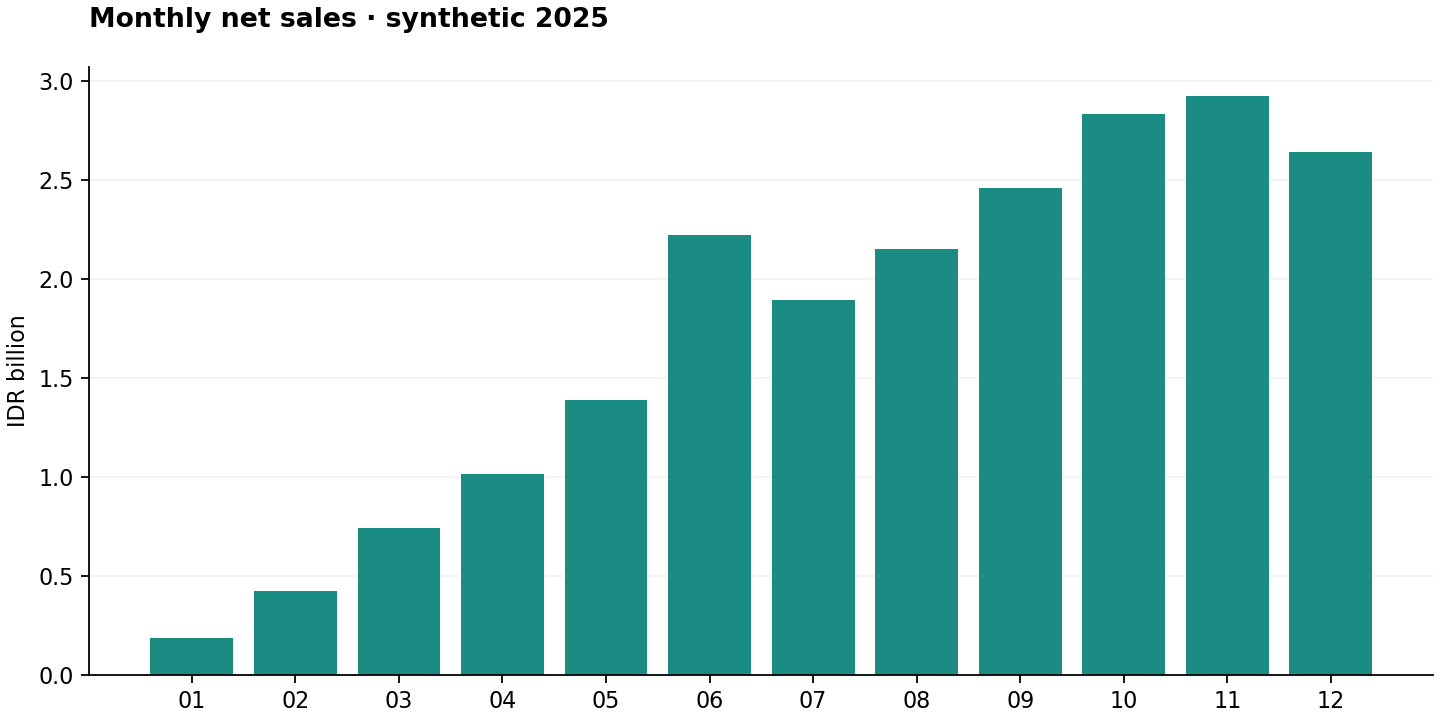

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root/'reports/charts/monthly_sales.png')))

## Interpretation
Read reports/insights.md. The generated seasonal pattern and repeat-buyer bias are assumptions, not discoveries about a real business. RFM uses the fixed full-year window.